In [69]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit
from scipy.stats import norm
from scipy.stats import chi2

# Stile comune con accento rosso del corso.
ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ORO = "#D79B00"
plt.rcParams.update({
    "figure.figsize": (8.2, 4.6),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "font.size": 11,
    "legend.frameon": False,
})

In [13]:
# Caricamento del file CSV
dati = np.genfromtxt(
    "dati_modello.csv",
    delimiter=",",
    names=True
)

# Estrazione delle colonne
x = dati["x_mm"]
y = dati["conteggi"]
sigma_y = dati["sigma_y"]

# Verifica lunghezze
if len(x)== len(y) == len(sigma_y):
   print("Le lunghezze degli array sono uguali")
else:
   print("Gli array non hanno la stessa lunghezza")

# Verifica valori finiti
if np.all(np.isfinite(x)):
   print("Tutti i valori di x sono finiti")
else:
   print("Non tutti i valori di x sono finiti")

if np.all(np.isfinite(y)):
   print("Tutti i valori di y sono finiti")
else:
   print("Non tutti i valori di y sono finiti")

if np.all(np.isfinite(sigma_y)):
   print("Tutti i valori di sigma_y sono finiti")
else:
   print("Non tutti i valori di sigma_y sono finiti")


# Verifica incertezze positive
if np.all(sigma_y > 0):
   print("Tutte le incertezze sono positive")
else:
   print("Almeno un'incertezza non è positiva")

# Verifica posizioni ordinate
if np.all(np.diff(x) > 0):
   print("Le posizioni sono ordinate")
else:
   print("Le posizioni non sono strettamente crescenti")

# Intervalli dei dati
print(f"Numero di punti:", len(x))
print(f"Intervallo x: [{x.min():.3f}, {x.max():.3f}] mm")
print(f"Intervallo y: [{y.min():.3f}, {y.max():.3f}] conteggi")
print(f"Intervallo sigma_y: [{sigma_y.min():.3f}, {sigma_y.max():.3f}] conteggi")

Le lunghezze degli array sono uguali
Tutti i valori di x sono finiti
Tutti i valori di y sono finiti
Tutti i valori di sigma_y sono finiti
Tutte le incertezze sono positive
Le posizioni sono ordinate
Numero di punti: 300
Intervallo x: [-5.000, 5.000] mm
Intervallo y: [35.000, 468.000] conteggi
Intervallo sigma_y: [5.916, 21.633] conteggi


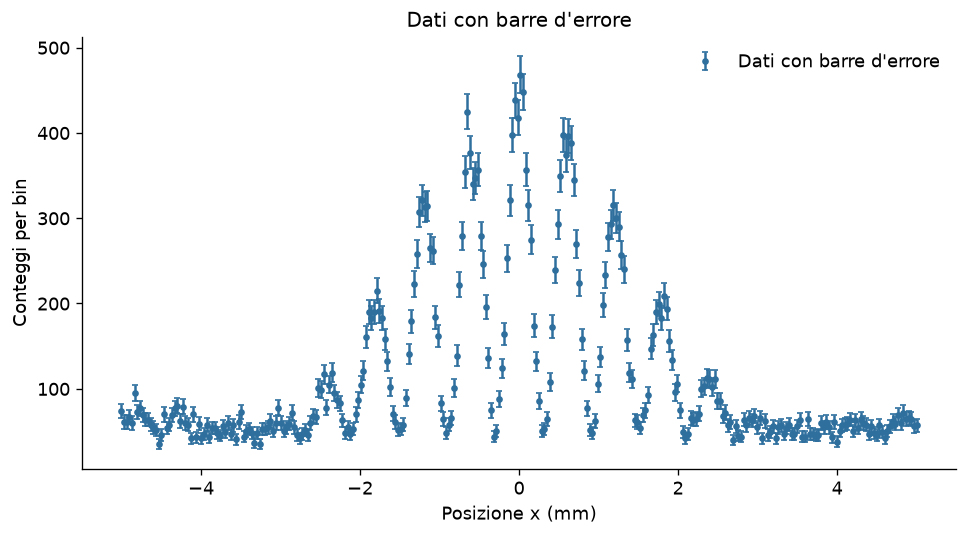

Fondo stimato: 59.50 conteggi/bin
Massimo centrale: 468.0
Distanza tra due picchi: 0.5
Primo minimo dell'inviluppo in x = 3.5


In [32]:
#Rappresentazione dati con barre d'errore
fig, ax = plt.subplots()

ax.errorbar(
    x, y, 
    yerr=sigma_y,
    fmt='o',
    markersize=3,
    capsize=2,
    color=AZZURRO,
    label="Dati con barre d'errore"
)

ax.set(xlabel="Posizione x (mm)", ylabel="Conteggi per bin", title="Dati con barre d'errore")
ax.legend()
plt.tight_layout()
plt.show()


# Selezione delle regioni laterali
maschera_laterale = (x < -4) | (x > 4)
# Stima del fondo come mediana dei conteggi selezionati
B_stimato = np.median(y[maschera_laterale])
print(f"Fondo stimato: {B_stimato:.2f} conteggi/bin")

# Massimo centrale
maschera_centrale = np.abs(x) < 0.3
massimo_centrale = np.max(y[maschera_centrale])
print("Massimo centrale:", massimo_centrale )


#distanza tra le frangie stimata come ampiezza intervallo/numero di minimi
distanza = 4/8  
print(f"Distanza tra due picchi:", distanza)          

# primo minimo dell'inviluppo
x_min=3.5 
print(f"Primo minimo dell'inviluppo in x =", x_min)

In [57]:
# Stime iniziali del fondo e dell'ampiezza
B_0 = B_stimato
I_0 = massimo_centrale-B_0

# stime iniziali dei parametri ricavati dal grafico
alpha_0 = np.pi/x_min          
delta_0 = np.pi/distanza

# vettore stime iniziali
p0 = [B_0, I_0, alpha_0, delta_0]

print(f"Stime iniziali dei parametri: \nB_0 = {p0[0]}, I_0 = {p0[1]}, alpha_0 = {p0[2]:.3f}, delta_0 = {p0[3]:.3f}")

# impostare i bounds
lower = [0.0, 0.0, 0.10, 1.2]
upper = [np.inf, np.inf, 3.0, 12.0]



Stime iniziali dei parametri: 
B_0 = 59.5, I_0 = 408.5, alpha_0 = 0.898, delta_0 = 6.283


Parametri ottimali:
B = 49.6 ± 0.6 conteggi
I = 397 ± 4 conteggi
alpha = 0.900 ± 0.006 1/mm
delta = 5.194 ± 0.005 1/mm
Matrice di correlazione:
[[ 1.      -0.27893  0.18376  0.00274]
 [-0.27893  1.       0.43388  0.00514]
 [ 0.18376  0.43388  1.       0.00545]
 [ 0.00274  0.00514  0.00545  1.     ]]


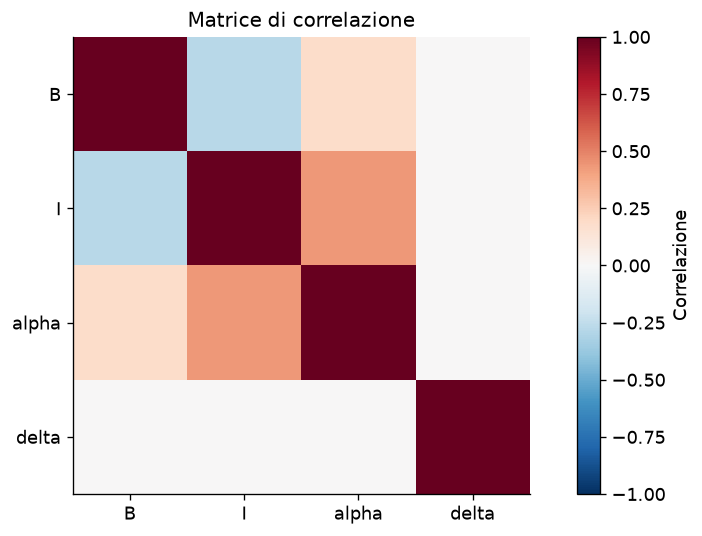

In [82]:
# Definizione funzione del modello
def E(x, alpha): 
    return np.sinc(alpha * x / np.pi) **2

def C(x, delta):
    return np.cos(delta * x) **2


#funzione principale
def mu(x, B, I, alpha, delta):
    return B + I * E(x,alpha) * C(x,delta)

# Esecuzione del fit
popt, pcov = curve_fit(
    mu, x, y,
    p0=p0,
    sigma=sigma_y,
    absolute_sigma=True,
    bounds=(lower,upper),
    maxfev=100000
)

# Parametri ottimali
B_fit, I_fit, alpha_fit, delta_fit = popt

# Incertezze sui parametri
incertezze_standard = np.sqrt(np.diag(pcov))

# Stampa dei parametri
print("Parametri ottimali:")
print(f"B = {B_fit:.1f} ± {incertezze_standard[0]:.1f} conteggi")
print(f"I = {I_fit:.0f} ± {incertezze_standard[1]:.0f} conteggi")
print(f"alpha = {alpha_fit:.3f} ± {incertezze_standard[2]:.3f} 1/mm")
print(f"delta = {delta_fit:.3f} ± {incertezze_standard[3]:.3f} 1/mm")


def covarianza_correlazione(cov):
    deviazioni = np.sqrt(np.diag(cov))
    return cov / np.outer(deviazioni, deviazioni)

# Matrice di correlazione
corr = covarianza_correlazione(pcov)

with np.printoptions(precision=5, suppress=True):
    print("Matrice di correlazione:")
    print(corr)

# Mappa di colore
plt.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
plt.colorbar(label="Correlazione")
plt.xticks(range(4), ["B", "I", "alpha", "delta"])
plt.yticks(range(4), ["B", "I", "alpha", "delta"])
plt.title("Matrice di correlazione")
plt.tight_layout()
plt.show()


# La coppia maggiormente correlata è costituita da I e alpha, 
# con coefficiente di correlazione 0.434, che indica una correlazione positiva moderata.
# I due parametri tendono a variare nella stessa direzione e i loro effetti sulla curva 
# possono essere parzialmente correlati.



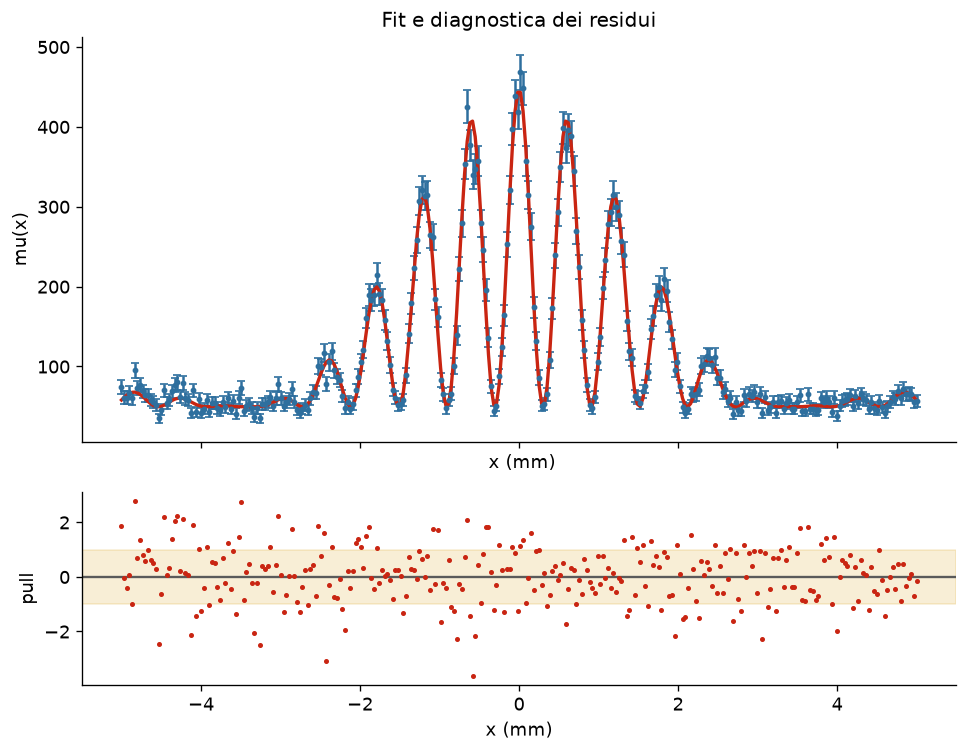

In [81]:
# Valori previsti dal modello
y_fit = mu(x, *popt)

# Residui e pull
residui = y - y_fit
pull = residui / sigma_y

# Gradi di libertà
N = len(y)
ndf = N - 4

# chi-quadro e chi-quadro ridotto
chi2_obs = np.sum(pull**2)
chi2_ridotto = chi2_obs / ndf

# p-value
p_value=chi2.sf(chi2_obs, ndf)

# costruzione figura
fig, ax = plt.subplots(
    2,1, figsize=(8.2,6.4), sharex=True,
    gridspec_kw={"height_ratios":[2.1,1]}
)

ax[0].errorbar(
    x, y,
    yerr=sigma_y,
    fmt='o',
    color=AZZURRO,
    markersize=2.5,
    capsize=2.5,
    label="Punti sperimentali"
)
ax[0].set(xlabel=" x (mm)", ylabel="mu(x)",  title="Fit e diagnostica dei residui")
ax[0].plot(x, y_fit, color=ROSSO, lw=2)

ax[1].axhline(0, color=GRIGIO, lw=1.4)
ax[1].axhspan(-1,1, color=ORO, alpha=0.16)
ax[1].plot(x, pull, 'o', markersize=2, color=ROSSO)
ax[1].set(xlabel="x (mm)", ylabel="pull")
fig.tight_layout()
plt.show()


